# Effect of Global and Local Ancestry on Age at Onset
RFmix2 results

##### Modules

In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from matplotlib import font_manager

import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

##### Fonts & Colors

In [2]:
# font style
locations = ['/home/eger/software/fonts']
font_files = font_manager.findSystemFonts(fontpaths = locations)
for file in font_files:
    font_manager.fontManager.addfont(file)
plt.rcParams['font.family'] = 'Aptos'

# font size
title_size = 24
label_size = 18
tick_size = 16

# colors
E280A_color = 'skyblue'
sex_color_dict = {1: 'mediumseagreen', 2: 'mediumpurple'}
anc_color_dict = {'EUR': 'dodgerblue', 'AMR': 'green', 'AFR': 'purple'}
apoe_color_dict = {'E2': 'midnightblue', 'E3': 'darkolivegreen', 'E4': 'darkgoldenrod'}

##### Inputs

In [18]:
DIR1 = '/home/eger/projects/E280A'
DIR2 = '/scratch/eger/projects/E280A_SNP_arrays/APOE_genotypes'
DIR3 = '/scratch/eger/projects/E280A_SNP_arrays/RFmix_LAI_v2/Tractor'
DIR4 = '/scratch/eger/projects/E280A_SNP_arrays/E280A_340/GENESIS_v2'
DIR5 = '/scratch/eger/projects/E280A_SNP_arrays/E280A_340/ADMIXTURE_v1'

orig_fam = os.path.join(DIR1, '2021.11.30-E280A-340_mac6.fam')
pheno = os.path.join(DIR1, 'E280A_cohorts.txt')
apoe = os.path.join(DIR2, 'APOE_genotypes_imputed.tsv')
pcair = os.path.join(DIR4, 'hgdp_1kg.AFR_AMR_EUR_unrelated_E280A_340.auto.hg38_pcair_PCs.txt')
fam1 = os.path.join(DIR5, 'E280A_340.auto.hg38.ext.pruned.fam') # ADMIXTURE
q1 = os.path.join(DIR5, 'E280A_340.auto.hg38.ext.pruned.3.Q') # ADMIXTURE

# AFR=0, AMR=1, EUR=2
dos0 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc0.dosage.txt')
dos1 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc1.dosage.txt')
dos2 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc2.dosage.txt')

hap0 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc0.hapcount.txt')
hap1 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc1.hapcount.txt')
hap2 = os.path.join(DIR3, 'Esc-Imputed-HiQual_R2-0.3.chr19.anc2.hapcount.txt')

##### Metadata

In [42]:
dff = pd.read_csv(fam, sep='\s+', header=None, 
                  names=['FID', 'IID', 'PAT', 'MAT', 'SEX', 'AAO'])
dfa = pd.read_csv(apoe, sep='\t', header=None, names=['IID', 'APOE']) 

dfa['APOE_H1'] = dfa['APOE'].apply(lambda x: x.split('/')[0])
dfa['APOE_H2'] = dfa['APOE'].apply(lambda x: x.split('/')[1])

# n = 340
final_set = list(dff['IID'])

# using the AAO from HudsonAlpha
df = dff.merge(dfa, on=['IID'], how='inner')

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_682298/496029390.py:1: SyntaxWarning: invalid escape sequence '\s'
  dff = pd.read_csv(fam, sep='\s+', header=None,


##### Global Ancestry data

In [43]:
dfq = pd.concat([pd.read_csv(fam1, sep='\s+', header=None, 
                    names=['FID', 'IID', 'FA', 'MO', 'SEX', 'PHENO'])[['IID']],
                 pd.read_csv(q1, header=None, sep=' ', names=['global_AMR', 'global_EUR', 'global_AFR'])],
                 axis=1)
dfp = pd.read_csv(pcair,header=None, sep='\s+')
dfp.columns = ['IID'] + ['PC'+str(i) for i in np.arange(1, dfp.shape[1])]

df = df.merge(dfq, on=['IID'], how='inner').merge(dfp[['IID', 'PC1', 'PC2']], on=['IID'], how='inner')

<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
<>:1: SyntaxWarning: invalid escape sequence '\s'
<>:5: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_682298/529122205.py:1: SyntaxWarning: invalid escape sequence '\s'
  dfq = pd.concat([pd.read_csv(fam1, sep='\s+', header=None,
/tmp/ipykernel_682298/529122205.py:5: SyntaxWarning: invalid escape sequence '\s'
  dfp = pd.read_csv(pcair,header=None, sep='\s+')


#### RFmix/Tractor outputs

In [44]:
df0 = pd.read_csv(dos0, sep='\t')
df1 = pd.read_csv(dos1, sep='\t')
df2 = pd.read_csv(dos2, sep='\t')

In [45]:
snps = ['rs429358', 'rs7412']

for snp in snps:
    df[snp+'_AFR_dos'] = df['IID'].map(df0.loc[df0['ID'] == snp, df0.columns[5:]].T.squeeze())
    df[snp+'_AMR_dos'] = df['IID'].map(df1.loc[df1['ID'] == snp, df1.columns[5:]].T.squeeze())
    df[snp+'_EUR_dos'] = df['IID'].map(df2.loc[df2['ID'] == snp, df2.columns[5:]].T.squeeze())

In [46]:
df0 = pd.read_csv(hap0, sep='\t')
df1 = pd.read_csv(hap1, sep='\t')
df2 = pd.read_csv(hap2, sep='\t')

In [47]:
for snp in snps:
    df[snp+'_AFR_hap'] = df['IID'].map(df0.loc[df0['ID'] == snp, df0.columns[5:]].T.squeeze())
    df[snp+'_AMR_hap'] = df['IID'].map(df1.loc[df1['ID'] == snp, df1.columns[5:]].T.squeeze())
    df[snp+'_EUR_hap'] = df['IID'].map(df2.loc[df2['ID'] == snp, df2.columns[5:]].T.squeeze())

In [48]:
for anc in anc_color_dict.keys():
    df_hap = df[df['rs429358_'+anc+'_hap'] != df['rs7412_'+anc+'_hap']]
    if not df_hap.empty:
        print(df_hap)

2 SNPs have matching anc for each individual \
Make a hap/hap ancestry column

In [49]:
anc_combos = ['EUR/EUR', 'AFR/EUR', 'AMR/EUR', 
              'AMR/AMR', 'AFR/AMR', 'AFR/AFR']

df['LAI'] = ''
df.loc[(df['rs429358_AFR_hap'] == 2), 'LAI'] = 'AFR/AFR'
df.loc[(df['rs429358_AFR_hap'] == 1) & (df['rs429358_AMR_hap'] == 1), 'LAI'] = 'AFR/AMR'
df.loc[(df['rs429358_AFR_hap'] == 1) & (df['rs429358_EUR_hap'] == 1), 'LAI'] = 'AFR/EUR'
df.loc[(df['rs429358_AMR_hap'] == 2), 'LAI'] = 'AMR/AMR'
df.loc[(df['rs429358_AMR_hap'] == 1) & (df['rs429358_EUR_hap'] == 1), 'LAI'] = 'AMR/EUR'
df.loc[(df['rs429358_EUR_hap'] == 2), 'LAI'] = 'EUR/EUR'

In [50]:
pd.pivot_table(df[['APOE', 'LAI']], index='APOE', columns='LAI', aggfunc=len, fill_value=0, margins=True)

LAI,AFR/AFR,AFR/AMR,AFR/EUR,AMR/AMR,AMR/EUR,EUR/EUR,All
APOE,,,,,,,
E2/E3,0,3,7,0,9,22,41
E2/E4,0,0,4,1,0,0,5
E3/E3,0,2,12,39,79,80,212
E3/E4,1,7,12,12,23,19,74
E4/E4,1,1,1,1,2,2,8
All,2,13,36,53,113,123,340


In [51]:
# both haps are the same ancestry
df['LAI_H1'] = np.where(df['LAI'].isin(['EUR/EUR', 'AMR/AMR', 'AFR/AFR']), 
                        df['LAI'].apply(lambda x: x.split('/')[0]), np.nan)
df['LAI_H2'] = np.where(df['LAI'].isin(['EUR/EUR', 'AMR/AMR', 'AFR/AFR']), 
                        df['LAI'].apply(lambda x: x.split('/')[-1]), np.nan)

# both alleles are the same
df['LAI_H1'] = np.where(df['APOE'].isin(['E3/E3', 'E4/E4']), 
                        df['LAI'].apply(lambda x: x.split('/')[0]), df['LAI_H1'])
df['LAI_H2'] = np.where(df['APOE'].isin(['E3/E3', 'E4/E4']), 
                        df['LAI'].apply(lambda x: x.split('/')[-1]), df['LAI_H2'])

In [52]:
# different alleles and different ancestries
# ['E2/E3', 'E3/E4', 'E2/E4']
for i, row in df[df['LAI_H1'].isna()].iterrows():
    ancestries = row['LAI'].split('/')
    
    if row['APOE'] == 'E2/E3':
        # E2 anc
        if (row['rs7412_AFR_dos'] == 1):
            df.loc[i, 'LAI_H1'] = 'AFR'
        elif (row['rs7412_AMR_dos'] == 1):
            df.loc[i, 'LAI_H1'] = 'AMR'
        else:
            df.loc[i, 'LAI_H1'] = 'EUR'
        # E3 anc
        if df.loc[i, 'LAI_H1'] == ancestries[0]:
            df.loc[i, 'LAI_H2'] = ancestries[1]
        else:
             df.loc[i, 'LAI_H2'] = ancestries[0]
    
    else: #E2/E4 or E3/E4
        # E4 anc
        if (row['rs429358_AFR_dos'] == 1):
            df.loc[i, 'LAI_H2'] = 'AFR'
        elif (row['rs429358_AMR_dos'] == 1):
            df.loc[i, 'LAI_H2'] = 'AMR'
        else:
            df.loc[i, 'LAI_H2'] = 'EUR'
        # E2 or E3 anc
        if df.loc[i, 'LAI_H2'] == ancestries[0]:
            df.loc[i, 'LAI_H1'] = ancestries[1]
        else:
             df.loc[i, 'LAI_H1'] = ancestries[0]

In [55]:
df = df[['FID', 'IID', 'SEX', 'AAO', 'APOE', 'APOE_H1', 'APOE_H2',
         'LAI', 'LAI_H1', 'LAI_H2', 'global_AMR', 'global_EUR', 'global_AFR', 'PC1', 'PC2',
       'rs429358_AFR_dos', 'rs429358_AMR_dos', 'rs429358_EUR_dos',
       'rs7412_AFR_dos', 'rs7412_AMR_dos', 'rs7412_EUR_dos',
       'rs429358_AFR_hap', 'rs429358_AMR_hap', 'rs429358_EUR_hap',
       'rs7412_AFR_hap', 'rs7412_AMR_hap', 'rs7412_EUR_hap']]

## APOE genotype & allele counts

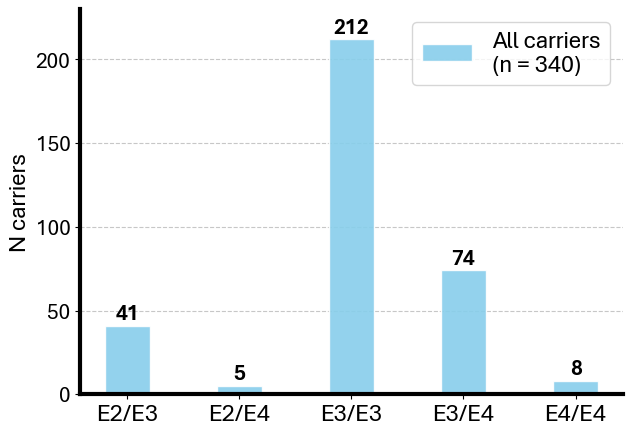

In [57]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
apoes = sorted(df['APOE'].unique())
x = np.arange(len(apoes))
bar_width = 0.4
text_gap = 7

apoe_counts = [df[(df.APOE == gt)].shape[0] for gt in apoes]
 
rects = ax.bar(x + bar_width, apoe_counts, edgecolor='white', 
               label='All carriers\n(n = '+str(df.shape[0])+')',
                 width=bar_width, color=E280A_color, 
                 alpha=0.9, zorder=2)

# add counts to top of bars
for i, v in enumerate(apoe_counts):
    ax.text(i+bar_width, v+text_gap, str(v), color='black', 
         fontweight='bold', fontsize=tick_size, ha='center', va='center')

ax.set_ylabel('N carriers', fontsize=label_size)
ax.set_ylim(0, 230)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(x+(bar_width))
ax.set_xticklabels(apoes, fontsize=label_size)
ax.legend(fontsize=label_size, loc='upper right')

plt.show()

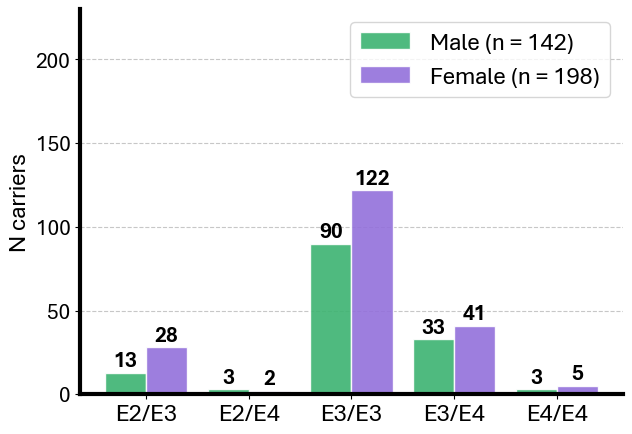

In [58]:
fig, ax = plt.subplots(1, 1, figsize=(7, 5))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
apoes = sorted(df['APOE'].unique())
x = np.arange(len(apoes))
bar_width = 0.4
text_gap = 7
multiplier = 0

apoe_m_counts = [df[(df.APOE == gt) & (df.SEX == 1)].shape[0] for gt in apoes]
apoe_f_counts = [df[(df.APOE == gt) & (df.SEX == 2)].shape[0] for gt in apoes]

for counts, sex in zip([apoe_m_counts, apoe_f_counts], ['Male', 'Female']):    
    rects = ax.bar(x + (bar_width * multiplier), counts, edgecolor='white',
                     label=sex+' (n = '+str(df[df.SEX == multiplier+1].shape[0])+')', 
                     width=bar_width, color=sex_color_dict[multiplier+1], 
                     alpha=0.9, zorder=2)
    
    # add counts to top of bars
    for i, v in enumerate(counts):
        if v != 0:
            if 'Male' in sex:
                ax.text(i, v + text_gap, str(v), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
            else:
                ax.text(i+bar_width, v + text_gap, str(v), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
    multiplier += 1

ax.set_ylabel('N carriers', fontsize=label_size)
ax.set_ylim(0, 230)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(x+(bar_width/2))
ax.set_xticklabels(apoes, fontsize=label_size)
ax.legend(fontsize=label_size)

plt.show()

In [59]:
allele_dict = {'E2': 0, 'E3': 0, 'E4': 0}
allele_m_dict = {'E2': 0, 'E3': 0, 'E4': 0}
allele_f_dict = {'E2': 0, 'E3': 0, 'E4': 0}

for i,row in df.iterrows():
    alleles = row['APOE'].split('/')
    for a in alleles:
        allele_dict[a] = allele_dict[a]+1
        if row['SEX'] == 1:
            allele_m_dict[a] = allele_m_dict[a]+1
        else:
            allele_f_dict[a] = allele_f_dict[a]+1

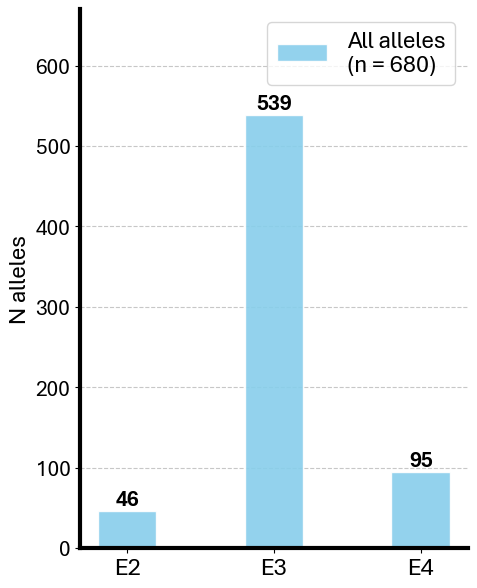

In [105]:
fig, ax = plt.subplots(1, 1, figsize=(5, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
x = np.arange(len(allele_dict))
bar_width = 0.4
text_gap = 14
 
rects = ax.bar(x + bar_width, list(allele_dict.values()), edgecolor='white', 
               label='All alleles\n(n = '+str(df.shape[0]*2)+')',
                 width=bar_width, color=E280A_color, 
                 alpha=0.9, zorder=2)

# add counts to top of bars
for i, v in enumerate(allele_dict.values()):
    ax.text(i+bar_width, v+text_gap, str(v), color='black', 
         fontweight='bold', fontsize=tick_size, ha='center', va='center')

ax.set_ylabel('N alleles', fontsize=label_size)
ax.set_ylim(0, 670)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(x+(bar_width))
ax.set_xticklabels(allele_dict.keys(), fontsize=label_size)
ax.legend(fontsize=label_size, loc='upper right')

plt.show()

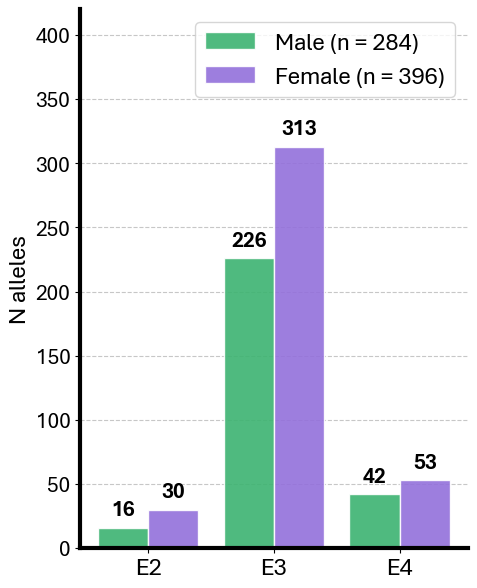

In [108]:
fig, ax = plt.subplots(1, 1, figsize=(5, 7))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
x = np.arange(len(allele_dict))
bar_width = 0.4
text_gap = 14
multiplier = 0

for a_dict, sex in zip([allele_m_dict, allele_f_dict], ['Male', 'Female']):    
    rects = ax.bar(x + (bar_width * multiplier), list(a_dict.values()), 
                   edgecolor='white', label=sex+' (n = '+str(sum(a_dict.values()))+')', 
                   width=bar_width, color=sex_color_dict[multiplier+1], 
                   alpha=0.9, zorder=2)
    
    # add counts to top of bars
    for i, v in enumerate(a_dict.values()):
        if v != 0:
            if sex == 'Male':
                ax.text(i, v + text_gap, str(v), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
            else:
                ax.text(i+bar_width, v + text_gap, str(v), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
    multiplier += 1

ax.set_ylabel('N alleles', fontsize=label_size)
ax.set_ylim(0, 420)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(x+(bar_width/2))
ax.set_xticklabels(allele_dict.keys(), fontsize=label_size)
ax.legend(fontsize=label_size, loc='upper right')

plt.show()

In [62]:
# Initialize dictionaries
allele_AFR_dict = {'E2': 0, 'E3': 0, 'E4': 0}
allele_AMR_dict = {'E2': 0, 'E3': 0, 'E4': 0}
allele_EUR_dict = {'E2': 0, 'E3': 0, 'E4': 0}

for anc in anc_color_dict.keys():
    if anc == 'AFR':
        allele_AFR_dict['E4'] = df['rs429358_AFR_dos'].sum()
        allele_AFR_dict['E2'] = df['rs7412_AFR_dos'].sum()
        allele_AFR_dict['E3'] = int((((df['rs429358_AFR_hap'].sum() + df['rs7412_AFR_hap'].sum())/2) - 
                                 allele_AFR_dict['E4'] - allele_AFR_dict['E2']))
    elif anc == 'AMR':
        allele_AMR_dict['E4'] = df['rs429358_AMR_dos'].sum()
        allele_AMR_dict['E2'] = df['rs7412_AMR_dos'].sum()
        allele_AMR_dict['E3'] = int(((df['rs429358_AMR_hap'].sum() + df['rs7412_AMR_hap'].sum())/2) - 
                                 allele_AMR_dict['E4'] - allele_AMR_dict['E2'])
    else:
        allele_EUR_dict['E4'] = df['rs429358_EUR_dos'].sum()
        allele_EUR_dict['E2'] = df['rs7412_EUR_dos'].sum() 
        allele_EUR_dict['E3'] = int(((df['rs429358_EUR_hap'].sum() + df['rs7412_EUR_hap'].sum())/2) - 
                                 allele_EUR_dict['E4'] - allele_EUR_dict['E2'])
        
print("African ancestry allele counts:", allele_AFR_dict)
print("American ancestry allele counts:", allele_AMR_dict)
print("European ancestry allele counts:", allele_EUR_dict)

African ancestry allele counts: {'E2': np.int64(10), 'E3': 24, 'E4': np.int64(19)}
American ancestry allele counts: {'E2': np.int64(1), 'E3': 191, 'E4': np.int64(40)}
European ancestry allele counts: {'E2': np.int64(35), 'E3': 324, 'E4': np.int64(36)}


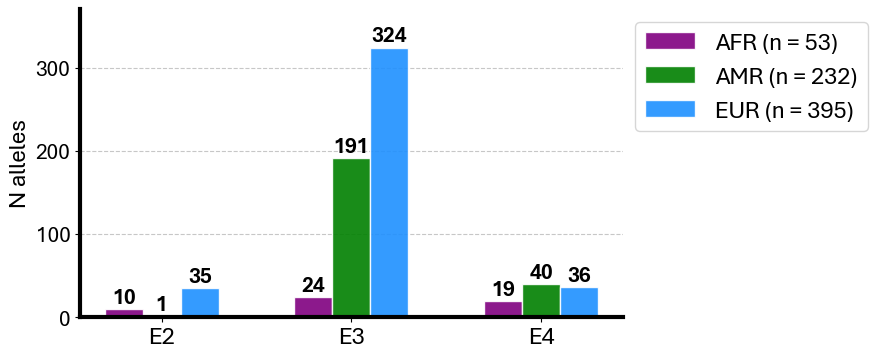

In [148]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
x = np.arange(len(allele_dict))
bar_width = 0.2
text_gap = 14
multiplier = 0

for a_dict, anc in zip([allele_AFR_dict, allele_AMR_dict, allele_EUR_dict], ['AFR', 'AMR', 'EUR']):    
    rects = ax.bar(x + (bar_width * multiplier), list(a_dict.values()), 
                   edgecolor='white', label=anc+' (n = '+str(sum(a_dict.values()))+')', 
                   width=bar_width, color=anc_color_dict[anc], 
                   alpha=0.9, zorder=2)
    # add counts to top of bars
    for i, count in enumerate(a_dict.values()):
        if count != 0:
            if anc == 'AFR':
                ax.text(i, count + text_gap, str(count), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
            else:
                ax.text(i+(bar_width*multiplier), count + text_gap, str(count), color='black', 
                         fontweight='bold', fontsize=tick_size, ha='center', va='center')
    multiplier += 1

ax.set_ylabel('N alleles', fontsize=label_size)
ax.set_ylim(0, 370)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(x+(bar_width))
ax.set_xticklabels(allele_dict.keys(), fontsize=label_size)
ax.legend(fontsize=label_size, bbox_to_anchor=(1, 1))

plt.show()

## Global ancestry ~ age at onset

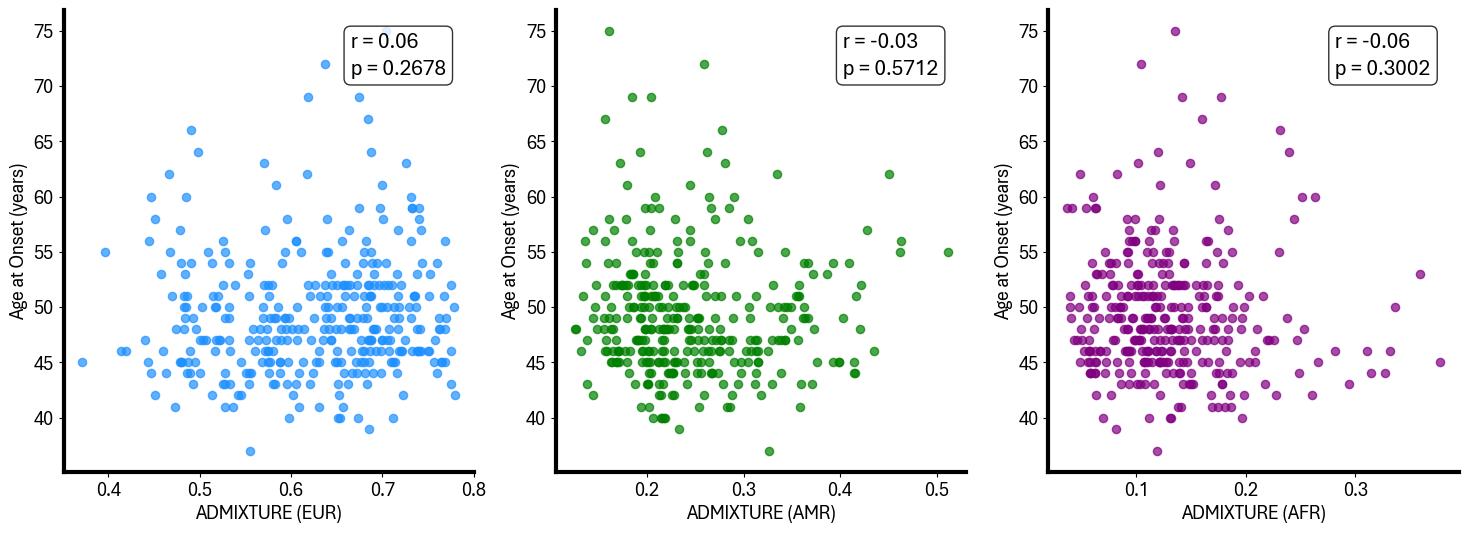

In [116]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i,anc in enumerate(anc_color_dict.keys()):
    x_var = 'global_'+anc
    y_var = 'AAO'
    
    
    ax = axes[i]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(3)
    ax.spines['left'].set_linewidth(3)

    ax.scatter(df[x_var], df[y_var], 
               color=anc_color_dict[anc],
               s=35, alpha=0.7, zorder=3)    

    # Calculate the linear regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        df[x_var], df[y_var])
        
    # regression line stats
    stats_text = '\n'.join(['r = %s' % str(r_value.round(2)),
                            'p = %s' % str(p_value.round(4))])
    ax.text(0.7, 0.95, stats_text,
        transform=ax.transAxes, fontsize=16, verticalalignment='top',
        horizontalalignment='left',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
        linespacing=1.5
    )

    ax.tick_params(axis='both', labelsize=14)
    ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
    ax.set_ylabel('Age at Onset (years)', fontsize=14)

plt.show()

In [162]:
# choose the biggest groups
# dfg = df[df['APOE'].isin(['E2/E3', 'E3/E3', 'E3/E4'])].reset_index(drop=True)
dfg = df[df['APOE'].isin(['E3/E3', 'E3/E4'])].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

In [163]:
# Fit linear model adjusting for sex
model = smf.ols('AAO ~ SEX + PC1 + PC2 + APOE + PC1*APOE + PC2*APOE', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.046
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                     2.217
Date:                Wed, 26 Mar 2025   Prob (F-statistic):             0.0416
Time:                        08:57:28   Log-Likelihood:                -883.46
No. Observations:                 286   AIC:                             1781.
Df Residuals:                     279   BIC:                             1807.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            45.5657      2.52

## APOE genotype ~ age at onset

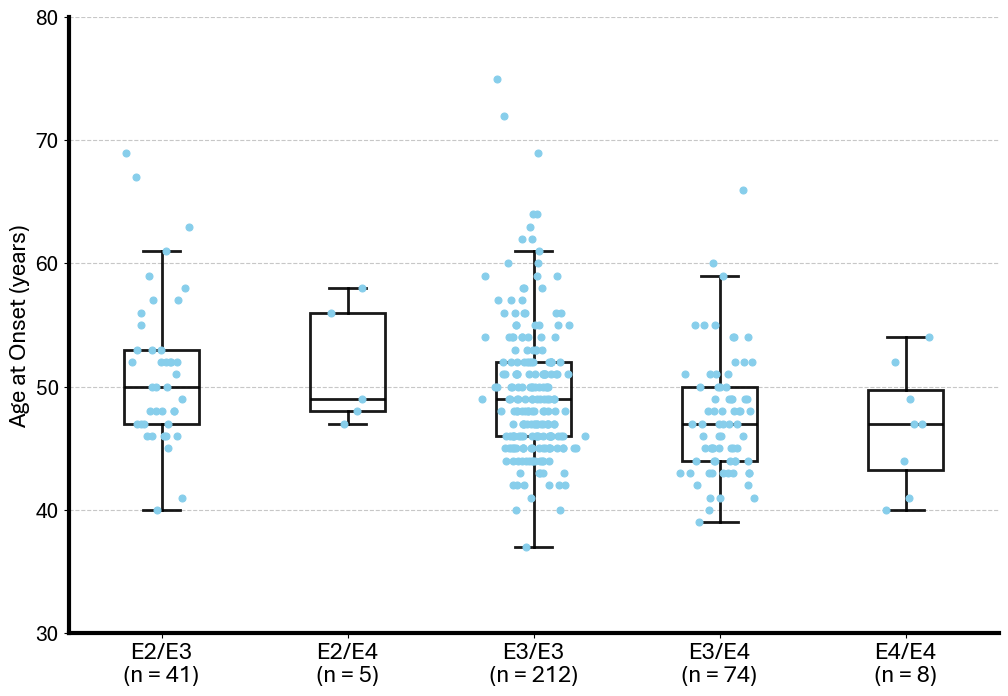

In [64]:
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

# bar spacing settings
apoes = sorted(df['APOE'].unique())
x_labels = []
box_width = 0.4

for i, geno in enumerate(apoes):
    ages = df[df['APOE'] == geno]['AAO']
    x_labels.append(geno+'\n'+'(n = '+str(len(ages))+')')
    
    box = ax.boxplot(ages, positions=[i+1],
                   widths=box_width,
                   medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                   whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                   capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                   boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                   showfliers=False, patch_artist=True, zorder=3)
    
    x = np.random.normal(i+1, 0.1, size=len(ages))
    scatter = ax.scatter(x, ages, 
                       color=E280A_color,  
                       linewidth=0.8, s=25, zorder=4)

ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)
#ax.legend(fontsize=label_size, loc='upper right')

plt.show()

### Stratify by APOE genotype

#### E3/E3

In [117]:
geno = 'E3/E3'
dfg = df[df['APOE'] == geno]

pd.pivot_table(dfg[['APOE', 'LAI']], index='APOE', columns='LAI', 
               aggfunc=len, fill_value=0)

LAI,AFR/AMR,AFR/EUR,AMR/AMR,AMR/EUR,EUR/EUR
APOE,,,,,
E3/E3,2,12,39,79,80


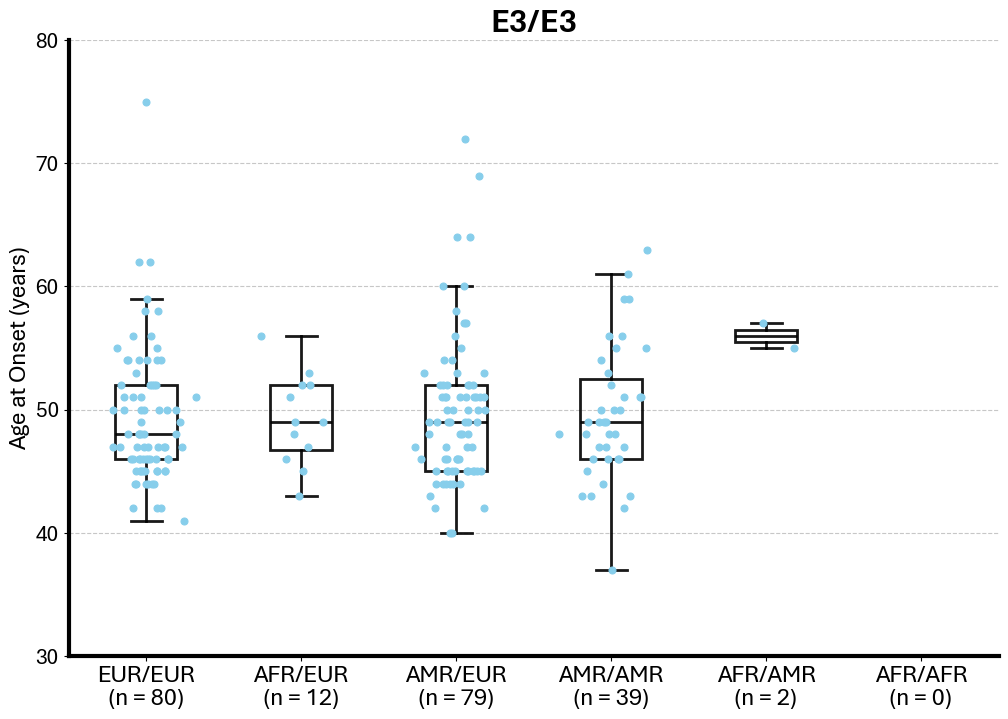

In [118]:
fig, ax = plt.subplots(1, 1, figsize=(12, 8))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.4

for i, combo in enumerate(anc_combos):
    ages = dfg[dfg['LAI'] == combo]['AAO']
    x_labels.append(combo+'\n'+'(n = '+str(len(ages))+')')

    # if len(ages) > 0:
    box = ax.boxplot(ages, positions=[i+1],
                   widths=box_width,
                   medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                   whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                   capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                   boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                   showfliers=False, patch_artist=True, zorder=3)
    
    x = np.random.normal(i+1, 0.1, size=len(ages))
    scatter = ax.scatter(x, ages, 
                       color=E280A_color,  
                       linewidth=0.8, s=25, zorder=4)

ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)
ax.set_title(geno, fontsize=title_size, fontweight='bold')

plt.show()

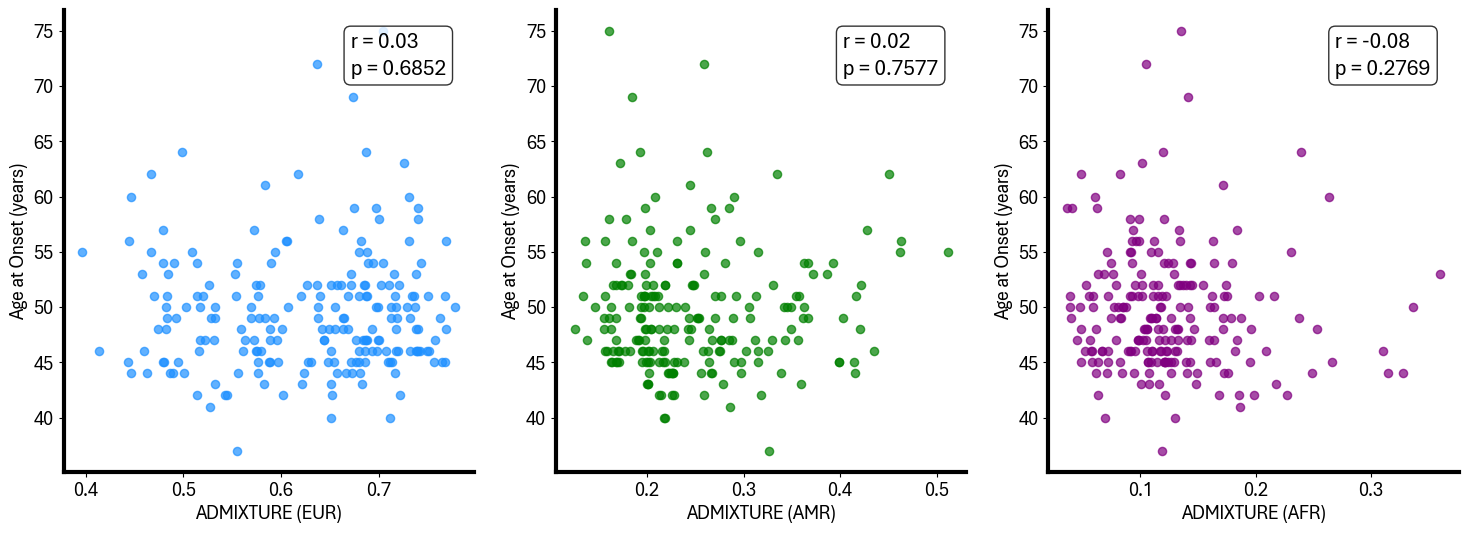

In [119]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i,anc in enumerate(anc_color_dict.keys()):
    x_var = 'global_'+anc
    y_var = 'AAO'
    
    
    ax = axes[i]
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_linewidth(3)
    ax.spines['left'].set_linewidth(3)

    ax.scatter(dfg[x_var], dfg[y_var], 
               color=anc_color_dict[anc],
               s=35, alpha=0.7, zorder=3)    

    # Calculate the linear regression line
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        dfg[x_var], dfg[y_var])
        
    # regression line stats
    stats_text = '\n'.join(['r = %s' % str(r_value.round(2)),
                            'p = %s' % str(p_value.round(4))])
    ax.text(0.7, 0.95, stats_text,
        transform=ax.transAxes, fontsize=16, verticalalignment='top',
        horizontalalignment='left',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3', alpha=0.8),
        linespacing=1.5
    )

    ax.tick_params(axis='both', labelsize=14)
    ax.set_xlabel('ADMIXTURE ('+anc+')', fontsize=14)
    ax.set_ylabel('Age at Onset (years)', fontsize=14)

plt.show()

#### E4/E4

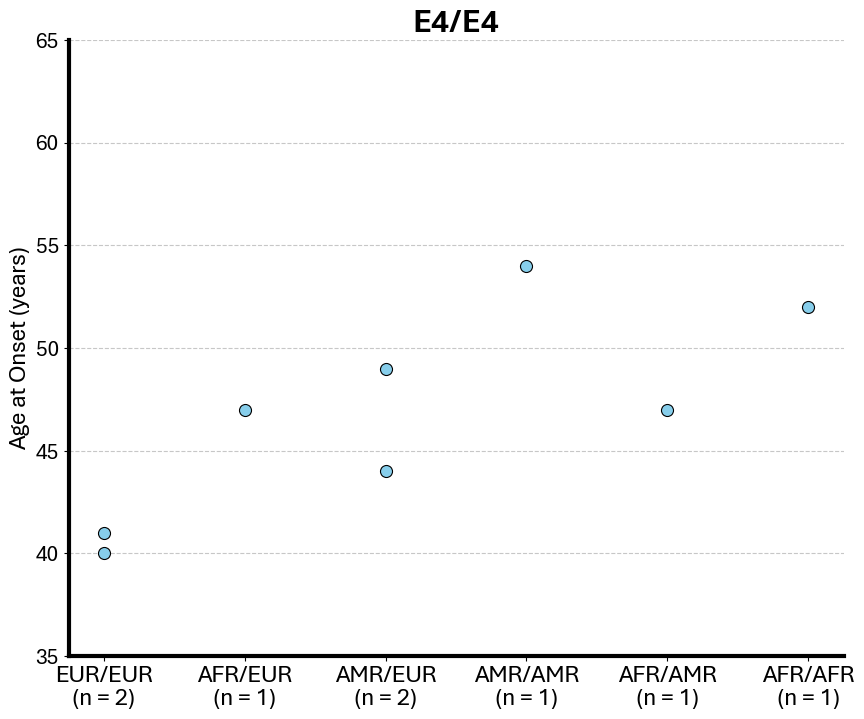

In [72]:
geno = 'E4/E4'
dfg = df[df['APOE'] == geno]

fig, ax = plt.subplots(1, 1, figsize=(10, 8))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.4

for i, combo in enumerate(anc_combos):
    ages = dfg[dfg['LAI'] == combo]['AAO']
    x_labels.append(combo+'\n'+'(n = '+str(len(ages))+')')
    
    x = np.ones(len(ages))+i
    scatter = ax.scatter(x, ages, 
                       color=E280A_color, edgecolor='k', 
                       linewidth=0.8, s=75, zorder=4)

ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
ax.set_ylim(35, 65)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticks(np.arange(1, len(anc_combos)+1))
ax.set_xticklabels(x_labels, fontsize=label_size)
ax.set_title(geno, fontsize=title_size, fontweight='bold')

plt.show()

#### E3/E4

In [135]:
geno = 'E3/E4'
dfg = df[df['APOE'] == geno].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

# Extract AAO values for each ancestry group
eur_ages = dfg[dfg['LAI_H2'] == 'EUR']['AAO']
afr_ages = dfg[dfg['LAI_H2'] == 'AFR']['AAO']
amr_ages = dfg[dfg['LAI_H2'] == 'AMR']['AAO']
AAO_dict = {'EUR': eur_ages, 'AFR': afr_ages, 'AMR': amr_ages}

# Check normality assumption for ANOVA
for anc, ages in AAO_dict.items():
    shapiro_p = stats.shapiro(ages.dropna()).pvalue
    print(f"Shapiro-Wilk Test for {anc}: p = {shapiro_p:.3g}")

# Levene's Test for Equal Variance
levene_stat, levene_p = stats.levene(eur_ages, afr_ages, amr_ages, center='median')
print(f"Levene’s Test for Homogeneity: W = {levene_stat:.3f}, p = {levene_p:.3g}")

Shapiro-Wilk Test for EUR: p = 0.118
Shapiro-Wilk Test for AFR: p = 0.118
Shapiro-Wilk Test for AMR: p = 0.0618
Levene’s Test for Homogeneity: W = 2.054, p = 0.136


In [136]:
# Fit linear model adjusting for sex and global ancestry
model = smf.ols('AAO ~ SEX + PC1 + PC2 + LAI_H2', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     1.187
Date:                Tue, 25 Mar 2025   Prob (F-statistic):              0.325
Time:                        19:31:23   Log-Likelihood:                -218.31
No. Observations:                  74   AIC:                             448.6
Df Residuals:                      68   BIC:                             462.4
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        47.4506      4.452     10.659

In [137]:
model = smf.ols('AAO ~ SEX + PC1 + PC2 + LAI_H1 + LAI_H2', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.127
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     1.374
Date:                Tue, 25 Mar 2025   Prob (F-statistic):              0.231
Time:                        19:31:29   Log-Likelihood:                -216.37
No. Observations:                  74   AIC:                             448.7
Df Residuals:                      66   BIC:                             467.2
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        45.5613      4.741      9.611

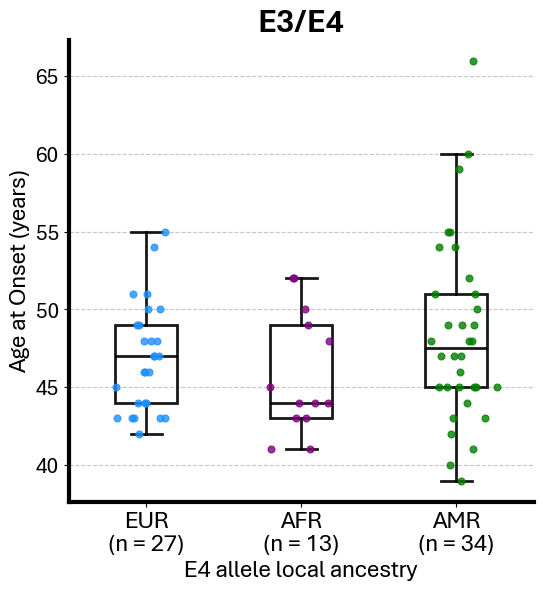

In [128]:
fig, ax = plt.subplots(1, 1, figsize=(6, 6))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.4

for i, anc in enumerate(['EUR', 'AFR', 'AMR']):
    ages = dfg[dfg['LAI_H2'] == anc]['AAO']
    x_labels.append(anc+'\n'+'(n = '+str(len(ages))+')')

    box = ax.boxplot(ages, positions=[i+1],
                   widths=box_width,
                   medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                   whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                   capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                   boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                   showfliers=False, patch_artist=True, zorder=3)
    
    x = np.random.normal(i+1, 0.1, size=len(ages))
    scatter = ax.scatter(x, ages, 
                       color=anc_color_dict[anc], alpha=0.8, 
                       linewidth=0.8, s=25, zorder=4)

ax.set_xlabel('E4 allele local ancestry', fontsize=label_size)
ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
#ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)
ax.set_title(geno, fontsize=title_size, fontweight='bold')

plt.show()

#### E2/E3

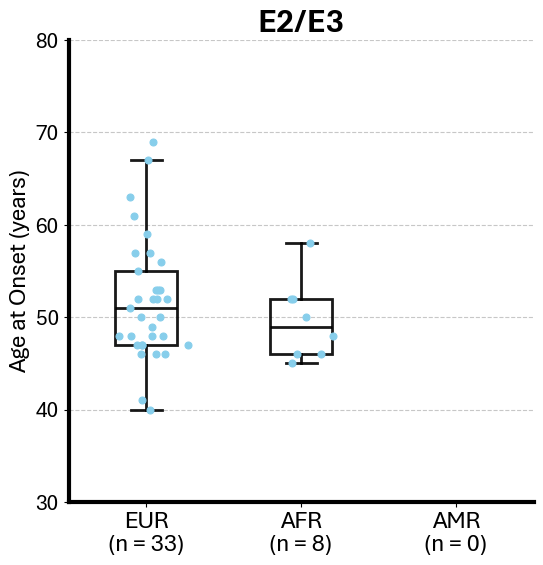

In [138]:
geno = 'E2/E3'
dfg = df[df['APOE'] == geno]

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.4

for i, anc in enumerate(['EUR', 'AFR', 'AMR']):
    ages = dfg[dfg['LAI_H1'] == anc]['AAO']
    x_labels.append(anc+'\n'+'(n = '+str(len(ages))+')')

    # if len(ages) > 0:
    box = ax.boxplot(ages, positions=[i+1],
                   widths=box_width,
                   medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                   whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                   capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                   boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                   showfliers=False, patch_artist=True, zorder=3)
    
    x = np.random.normal(i+1, 0.1, size=len(ages))
    scatter = ax.scatter(x, ages, 
                       color=E280A_color,  
                       linewidth=0.8, s=25, zorder=4)

ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)
ax.set_title(geno, fontsize=title_size, fontweight='bold')

plt.show()

#### E2/E4

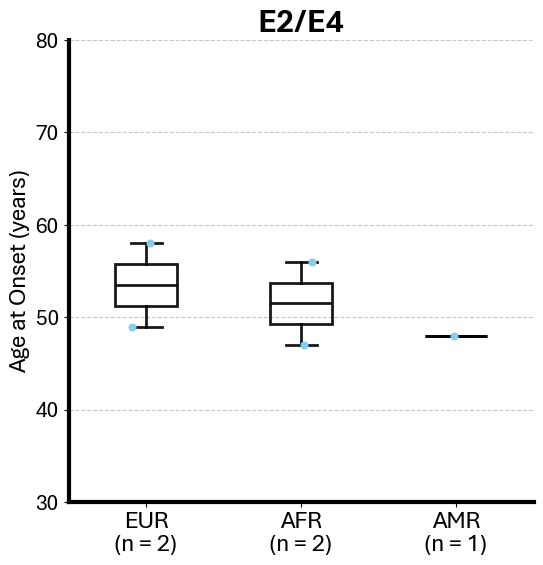

In [139]:
geno = 'E2/E4'
dfg = df[df['APOE'] == geno]

fig, ax = plt.subplots(1, 1, figsize=(6, 6))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.4

for i, anc in enumerate(['EUR', 'AFR', 'AMR']):
    ages = dfg[dfg['LAI_H1'] == anc]['AAO']
    x_labels.append(anc+'\n'+'(n = '+str(len(ages))+')')

    # if len(ages) > 0:
    box = ax.boxplot(ages, positions=[i+1],
                   widths=box_width,
                   medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                   whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                   capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                   boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                   showfliers=False, patch_artist=True, zorder=3)
    
    x = np.random.normal(i+1, 0.1, size=len(ages))
    scatter = ax.scatter(x, ages, 
                       color=E280A_color,  
                       linewidth=0.8, s=25, zorder=4)

ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)
ax.set_title(geno, fontsize=title_size, fontweight='bold')

plt.show()

In [82]:
dfg[['FID', 'IID', 'SEX', 'AAO', 'APOE', 'APOE_H1', 'APOE_H2',
       'LAI', 'LAI_H1', 'LAI_H2']]

,FID,IID,SEX,AAO,APOE,APOE_H1,APOE_H2,LAI,LAI_H1,LAI_H2
38,F-12176,B2_12233,2,56,E2/E4,E2,E4,AFR/EUR,AFR,EUR
65,F-183,9335,1,49,E2/E4,E2,E4,AFR/EUR,EUR,AFR
148,F-570,763,1,48,E2/E4,E2,E4,AMR/AMR,AMR,AMR
244,F-6800,6800,2,58,E2/E4,E2,E4,AFR/EUR,EUR,AFR
255,F-8047,8053,1,47,E2/E4,E2,E4,AFR/EUR,AFR,EUR


## Age at Onset Models

#### Model 1: AAO ~ Sex + APOE + LA + LA*APOE
based of Rajabli et al. (2018) \
LA must be the same for both alleles \
includes E3/E3, E3/E4, and E4/E4

In [83]:
dfg = df[(df['APOE'].isin(['E3/E3', 'E3/E4', 'E4/E4'])) & 
        (df['LAI_H1'] == df['LAI_H2'])].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

pd.pivot_table(dfg[['APOE', 'LAI']], index='APOE', columns='LAI', 
               aggfunc=len, fill_value=0, margins=True)

LAI,AFR/AFR,AMR/AMR,EUR/EUR,All
APOE,,,,
E3/E3,0,39,80,119
E3/E4,1,12,19,32
E4/E4,1,1,2,4
All,2,52,101,155


In [84]:
# Fit linear model adjusting for sex
model = smf.ols('AAO ~ SEX + PC1 + PC2 + APOE + LAI + LAI*APOE', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.094
Model:                            OLS   Adj. R-squared:                  0.031
Method:                 Least Squares   F-statistic:                     1.486
Date:                Mon, 24 Mar 2025   Prob (F-statistic):              0.150
Time:                        15:27:26   Log-Likelihood:                -473.39
No. Observations:                 155   AIC:                             968.8
Df Residuals:                     144   BIC:                             1002.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

In [88]:
dfg = df[(df['APOE'].isin(['E3/E3', 'E3/E4'])) | 
    ((df['APOE'] == 'E4/E4') & (df['LAI_H1'] == df['LAI_H2']))].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

pd.pivot_table(dfg[['APOE', 'LAI']], index='APOE', columns='LAI', 
               aggfunc=len, fill_value=0, margins=True)

LAI,AFR/AFR,AFR/AMR,AFR/EUR,AMR/AMR,AMR/EUR,EUR/EUR,All
APOE,,,,,,,
E3/E3,0,2,12,39,79,80,212
E3/E4,1,7,12,12,23,19,74
E4/E4,1,0,0,1,0,2,4
All,2,9,24,52,102,101,290


In [89]:
# Fit linear model adjusting for sex
model = smf.ols('AAO ~ SEX + PC1 + PC2 + APOE + LAI_H2 + LAI_H2*APOE', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.072
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     2.173
Date:                Mon, 24 Mar 2025   Prob (F-statistic):             0.0196
Time:                        15:36:09   Log-Likelihood:                -892.71
No. Observations:                 290   AIC:                             1807.
Df Residuals:                     279   BIC:                             1848.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

In [143]:
dfg = df[((df['APOE'] == 'E3/E4') | 
        ((df['APOE'] == 'E3/E3') & (df['LAI_H1'] == df['LAI_H2']))) & 
          (~df['LAI'].str.contains('AFR'))].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

pd.pivot_table(dfg[['APOE', 'LAI']], index='APOE', columns='LAI', 
               aggfunc=len, fill_value=0, margins=True)

LAI,AMR/AMR,AMR/EUR,EUR/EUR,All
APOE,,,,
E3/E3,39,0,80,119
E3/E4,12,23,19,54
All,51,23,99,173


In [144]:
# Fit linear model adjusting for sex
model = smf.ols('AAO ~ SEX + PC1 + PC2 + APOE + LAI_H2 + LAI_H2*APOE', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.047
Model:                            OLS   Adj. R-squared:                  0.013
Method:                 Least Squares   F-statistic:                     1.366
Date:                Tue, 25 Mar 2025   Prob (F-statistic):              0.231
Time:                        19:54:14   Log-Likelihood:                -530.30
No. Observations:                 173   AIC:                             1075.
Df Residuals:                     166   BIC:                             1097.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept         

In [149]:
dfg = df[(df['APOE'].isin(['E3/E3', 'E3/E4']) & 
          (df['LAI_H1'] == df['LAI_H2'])) & 
          (~df['LAI'].str.contains('AFR'))].reset_index(drop=True)

# covert sex to cat variable
dfg['SEX'] = dfg['SEX'] - 1 

pd.pivot_table(dfg[['APOE', 'LAI']], index='APOE', columns='LAI', 
               aggfunc=len, fill_value=0, margins=True)

LAI,AMR/AMR,EUR/EUR,All
APOE,,,
E3/E3,39,80,119
E3/E4,12,19,31
All,51,99,150


In [150]:
# Fit linear model adjusting for sex
model = smf.ols('AAO ~ SEX + PC1 + PC2 + APOE + LAI + LAI*APOE', data=dfg).fit()

# Print model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    AAO   R-squared:                       0.048
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     1.196
Date:                Tue, 25 Mar 2025   Prob (F-statistic):              0.312
Time:                        20:05:25   Log-Likelihood:                -460.54
No. Observations:                 150   AIC:                             935.1
Df Residuals:                     143   BIC:                             956.1
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

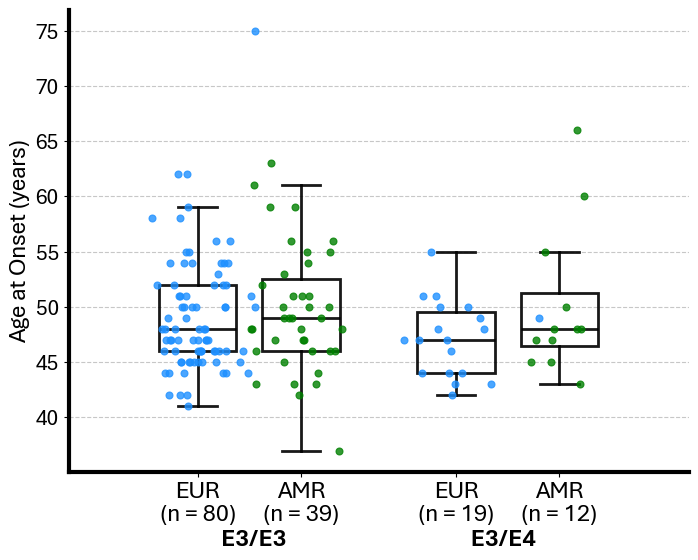

In [159]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.grid(True, axis='y', linestyle='--', alpha=0.7, zorder=0)

x_labels = []
box_width = 0.3

for i, geno in enumerate(['E3/E3', 'E3/E4']):
    dfe = dfg[dfg['APOE'] == geno]
    for j, anc in enumerate(['EUR', 'AMR']):
        ages = dfe[dfe['LAI_H2'] == anc]['AAO']
        x_labels.append(anc+'\n'+'(n = '+str(len(ages))+')')
    
        box = ax.boxplot(ages, positions=[i+(j*0.4)],
                       widths=box_width,
                       medianprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker median line
                       whiskerprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker whiskers
                       capprops=dict(color='black', alpha=0.9, linewidth=2),  # Thicker caps at whisker ends
                       boxprops=dict(facecolor='none', edgecolor='black', alpha=0.9, linewidth=2),  # Thicker box outlines
                       showfliers=False, patch_artist=True, zorder=3)
        
        x = np.random.normal(i+(j*0.4), 0.1, size=len(ages))
        scatter = ax.scatter(x, ages, 
                           color=anc_color_dict[anc], alpha=0.8, 
                           linewidth=0.8, s=25, zorder=4)

ax.set_xlabel('E3/E3                                    E3/E4', fontsize=label_size, fontweight='bold')
ax.set_ylabel('Age at Onset (years)', fontsize=label_size)
#ax.set_ylim(30, 80)
ax.tick_params(axis='y', labelsize=tick_size)
ax.set_xticklabels(x_labels, fontsize=label_size)

plt.show()